# Part A · Nine charts, rebuilt and taken apart

**Ali Afzal** · BSAI-7B-102 · Data Visualization · Week 5

This week's nine charts are arithmetically right, correctly parsed and carefully drawn. What lies in each
one is **the encoding or the geography**: which channel carried which variable, or which boundaries carved
up the land. Every case rebuilds the published chart to its self-check, rules out the first objection with
data, names the lying channel or boundary with the number that proves it, and plots a redesign.

Every figure shows the published chart on the left (**AS PUBLISHED**) and my redesign on the right. Maps use
`geolib`'s equal-area projection, because colour over an area makes area the encoding channel.

In [1]:
import itertools
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import geolib as g
from vizlib import PALETTE, save_fig, style_defaults

DATA = Path("data")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)
style_defaults(dpi=100)
BLUE, ORANGE, GREEN = PALETTE["series"]
GREY, INK, SOFT = PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
SOURCE = "Source: synthetic course data, CDB601220 Week 5. Boundaries: districts.geojson (course file, fictional federation)."
NUM = ["gdp_pc", "healthcare_access", "urban_pct", "median_age", "cases_per_100k"]


def wrap(text, width=55):
    return textwrap.fill(text, width)


def published(ax, claim):
    ax.set_title(wrap(f"AS PUBLISHED: “{claim}”", 60), fontsize=10, color=SOFT)


def save(fig, name, note=""):
    save_fig(fig, CHARTS / name, note=f"{note}  {SOURCE}".strip())


def per100k(df):
    return df.cases / df.population * 1e5


hi = pd.read_csv(DATA / "health_indicators.csv")
feats = g.read_geojson(DATA / "districts.geojson")
dh = pd.read_csv(DATA / "district_health.csv").assign(rate=per100k)

---
## 1 · "Population and healthcare access are unrelated — the large countries are spread right across the range"

Recipe: `ax.scatter(df.gdp_pc, df.healthcare_access, s=df.pop_m**2)` on a log x-axis.

In [2]:
s_pub = hi.pop_m ** 2
print(f"{len(hi)} marks; largest/smallest area: {s_pub.max() / s_pub.min():,.0f}x")
print(f"countries under 2.0 M people: {(hi.pop_m < 2).sum()}; their s ranges "
      f"{s_pub[hi.pop_m < 2].min():.2f}-{s_pub[hi.pop_m < 2].max():.2f} pt^2 (a single point is 1 pt^2)")
print(f"population spread {hi.pop_m.max() / hi.pop_m.min():.0f}x -> honest area ratio {hi.pop_m.max() / hi.pop_m.min():.0f}x, "
      f"diameter ratio {np.sqrt(hi.pop_m.max() / hi.pop_m.min()):.1f}x")

60 marks; largest/smallest area: 346,921x
countries under 2.0 M people: 9; their s ranges 0.36-3.61 pt^2 (a single point is 1 pt^2)
population spread 589x -> honest area ratio 589x, diameter ratio 24.3x


**Self-check:** 60 marks, and the brief's "589×" is the ratio of the *populations*. With `s = pop**2`,
the area ratio is 589² ≈ **346,921×**. The 9 countries under 2.0 M people get `s` values of 0.36–3.6 pt²,
about the size of a single point or smaller.

**The conclusion it invites.** Population tells you nothing about healthcare access. Two giant bubbles sit
at different heights, and nothing else is visible.

**The decoy.** "The log x-axis distorts it." It doesn't. GDP per capita spreads multiplicatively ($283 to
$120,219), and a log axis is the honest scale for that. The x and y channels are fine.

**The mechanism.** `s` is **area** in points², so `s = pop**2` makes area grow with the *square* of
population, which means the radius grows linearly. One country of 353 M is drawn 346,921× the area of
one of 0.6 M, not 589×. Two countries (353 M and 238 M) take up almost all the ink, nine shrink below a
visible mark, and the eye reads "two big bubbles at different heights" as "no relationship". Measured with
the variable rather than read off ink, the link is weak but positive: r(log pop, access) = +0.27.

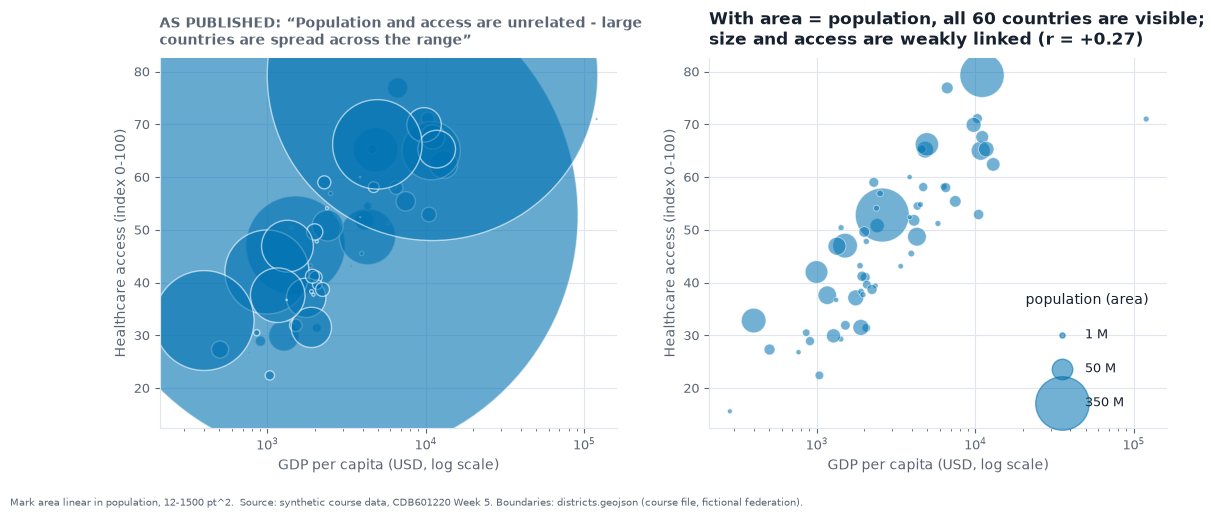

In [3]:
LO, HI = 12, 1500


def area_pt2(pop):
    """Area, not radius: linear in population between the smallest and largest country."""
    return LO + (HI - LO) * (pop - hi.pop_m.min()) / (hi.pop_m.max() - hi.pop_m.min())


fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8))
a.scatter(hi.gdp_pc, hi.healthcare_access, s=s_pub, color=BLUE, alpha=0.6, edgecolor="white")
a.set_xscale("log")
a.set_xlabel("GDP per capita (USD, log scale)")
a.set_ylabel("Healthcare access (index 0-100)")
published(a, "Population and access are unrelated - large countries are spread across the range")

b.scatter(hi.gdp_pc, hi.healthcare_access, s=area_pt2(hi.pop_m), color=BLUE, alpha=0.55, edgecolor="white", lw=0.6)
b.set_xscale("log")
b.set_xlabel("GDP per capita (USD, log scale)")
b.set_ylabel("Healthcare access (index 0-100)")
for v in (1, 50, 350):
    b.scatter([], [], s=area_pt2(v), color=BLUE, alpha=0.55, label=f"{v:g} M")
b.legend(title="population (area)", loc="lower right", labelspacing=1.6, borderpad=1)
r = np.corrcoef(np.log(hi.pop_m), hi.healthcare_access)[0, 1]
b.set_title(wrap(f"With area = population, all 60 countries are visible; size and access are weakly linked (r = {r:+.2f})"))
save(fig, "a1_radius_not_area.png", f"Mark area linear in population, {LO}-{HI} pt^2.")

**The redesign.** The same chart, with population driving **area** (`s` is linear in population, between
12 and 1,500 pt²) and a size legend with real values. Every country is visible and the two giants no
longer swallow the plot. That's a decision inside the chart, not a new chart type.

---
## 2 · "The outbreak is concentrated in the three districts around the capital"

Recipe: join on `code`, colour districts by `cases` with five natural breaks on a sequential blue ramp, and
list the top three.

In [4]:
codes = [f["code"] for f in feats]
unmatched = set(codes) ^ set(dh.code)
print(f"{len(dh)} districts, {dh.cases.sum():,} cases, population {dh.population.sum():,}; join failures: {len(unmatched)}")
print("top 3 by count:", dh.nlargest(3, "cases").code.tolist())

24 districts, 30,564 cases, population 57,857,000; join failures: 0
top 3 by count: ['D17', 'D13', 'D09']


**Self-check:** 24 districts, 30,564 cases, 57,857,000 people, top three by count D17, D13, D09, and 0
join failures. ✓

**The conclusion it invites.** The capital region is the hotspot, so send resources there.

**The decoy.** "Natural breaks exaggerate the top." The classification isn't the problem. Any scheme puts
D17 on top of a count map, because D17 has the most people.

In [5]:
r_cp = dh[["cases", "population"]].corr().iloc[0, 1]
r_rp = dh[["rate", "population"]].corr().iloc[0, 1]
top_c, top_r = dh.nlargest(3, "cases"), dh.nlargest(3, "rate")
print(f"r(cases, population) = {r_cp:+.3f}    r(rate, population) = {r_rp:+.3f}")
print(f"top 3 by count: {top_c.code.tolist()}  populations {(top_c.population / 1e6).round(1).tolist()} M")
print(f"top 3 by rate:  {top_r.code.tolist()}  populations {(top_r.population / 1e6).round(1).tolist()} M")
print(f"overlap: {len(set(top_c.code) & set(top_r.code))}")
print(f"pooled national rate {dh.cases.sum() / dh.population.sum() * 1e5:.1f} per 100,000")

r(cases, population) = +0.986    r(rate, population) = -0.000
top 3 by count: ['D17', 'D13', 'D09']  populations [11.0, 6.3, 6.9] M
top 3 by rate:  ['D19', 'D20', 'D21']  populations [1.8, 1.3, 1.1] M
overlap: 0
pooled national rate 52.8 per 100,000


**The mechanism.** A raw-count choropleth is a population map. r(cases, population) = **+0.986**, so the
colour is nearly a census. Once the cases are divided by the people at risk, r(rate, population) =
**−0.000**. The top three by count (6.3–11.0 M people each) and the top three by rate (D19, D20, D21, with
1.1–1.8 M people) share **no** districts. The published map points at the most populous districts,
not the most affected.

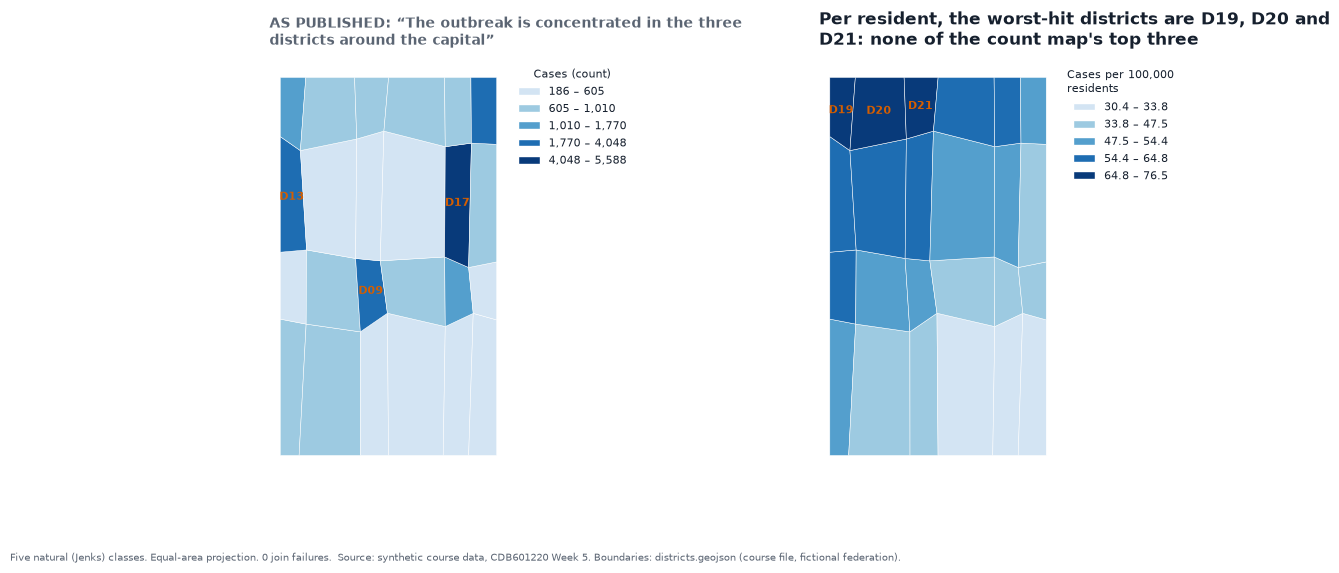

In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5.4))
g.choropleth(a, feats, dict(zip(dh.code, dh.cases)), "natural", 5, legend_title="Cases (count)",
             )
published(a, "The outbreak is concentrated in the three districts around the capital")
g.choropleth(b, feats, dict(zip(dh.code, dh.rate)), "natural", 5, fmt="{:.1f}",
             legend_title="Cases per 100,000\nresidents")
b.set_title(wrap("Per resident, the worst-hit districts are D19, D20 and D21: none of the count map's top three"))
for ax, top in ((a, top_c), (b, top_r)):
    pts = {f["code"]: g.representative_point(f["ring"]) for f in feats}
    lat_ts = float(np.mean([p[1] for f in feats for p in f["ring"]]))
    for c in top.code:
        x, y = g.equal_area_xy([pts[c][0]], [pts[c][1]], lat_ts=lat_ts)
        ax.text(x[0], y[0], c, ha="center", va="center", fontsize=8, fontweight="bold", color=ORANGE)
save(fig, "a2_count_vs_rate.png", "Five natural (Jenks) classes. Equal-area projection. 0 join failures.")

**The redesign.** Same boundaries, same scheme, same ramp, and a different numerator over a denominator:
cases **per 100,000 residents**, with the denominator written in the legend title.

---
## 3 · "GDP per capita barely varies across the sample"

Recipe: min–max scale all five numeric columns and draw a parallel coordinates plot.

In [7]:
mm = g.scale_frame(hi, NUM, "minmax")
print(f"countries below 0.10 on the gdp_pc axis: {(mm.gdp_pc < 0.10).sum()} of {len(mm)}; median {mm.gdp_pc.median():.3f}")
top = hi.gdp_pc.nlargest(2)
print(f"largest gdp_pc ${top.iloc[0]:,} ({hi.loc[top.index[0], 'country']}) = {top.iloc[0] / top.iloc[1]:.1f}x the next (${top.iloc[1]:,})")

countries below 0.10 on the gdp_pc axis: 58 of 60; median 0.017
largest gdp_pc $120,219 (Aldonia) = 9.2x the next ($13,009)


**Self-check:** 58 of 60 below 0.10, median 0.017. ✓

**The conclusion it invites.** GDP is basically the same everywhere, so it can't explain anything.

**The decoy.** "Aldonia is a data error, so drop it." Nothing says so. The data dictionary calls it "a
real kind of country" (a small, rich state), and its other values are ordinary. Deleting it would be
hiding a real country to fix a scaling choice.

In [8]:
spread = hi.gdp_pc.quantile([0.1, 0.9])
print(f"10th-90th percentile of gdp_pc: ${spread.iloc[0]:,.0f} to ${spread.iloc[1]:,.0f} ({spread.iloc[1] / spread.iloc[0]:.0f}x)")
logmm = g.scale_frame(hi.assign(gdp_pc=np.log10(hi.gdp_pc)), NUM, "minmax")
print(f"median position on the axis after log10 then min-max: {logmm.gdp_pc.median():.2f}")

10th-90th percentile of gdp_pc: $988 to $10,551 (11x)
median position on the axis after log10 then min-max: 0.35


**The mechanism.** Min–max scaling divides by the range, and one country, Aldonia at $120,219 (9.2× the
next), *is* the range. Everyone else is crushed into the bottom tenth. Between the 10th and 90th percentile
GDP varies **11-fold** ($988 to $10,551). The axis is flat because of the scaling, not the
data. GDP per capita is multiplicative, so log it first. The median then sits at 0.35 and the spread
comes back.

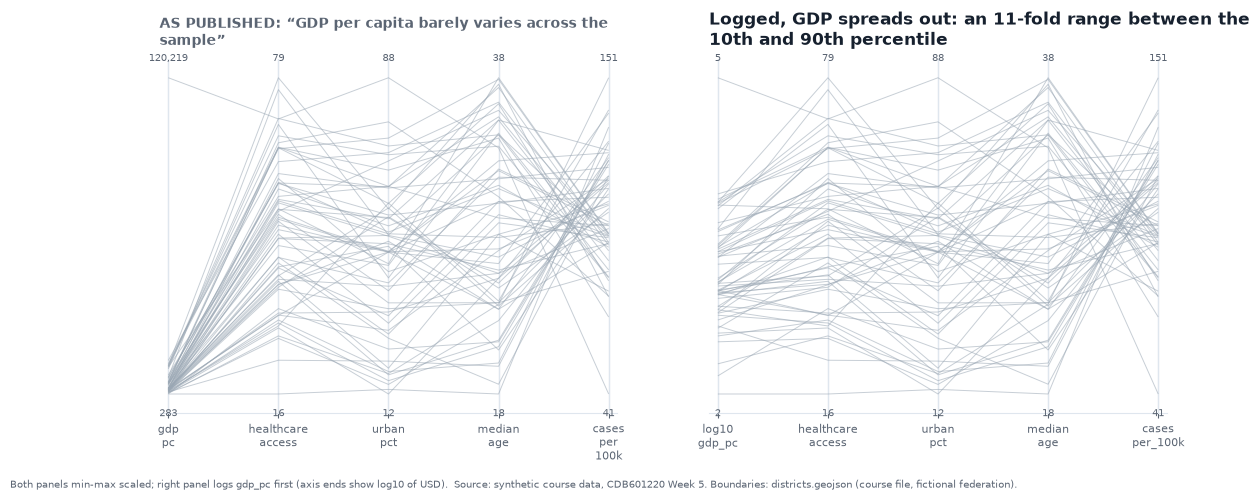

In [9]:
chain = ["healthcare_access", "cases_per_100k", "urban_pct", "median_age", "gdp_pc"]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6))
g.pcp(a, hi, NUM, "minmax")
published(a, "GDP per capita barely varies across the sample")
g.pcp(b, hi.assign(gdp_pc=np.log10(hi.gdp_pc)), NUM, "minmax")
b.set_xticks(range(5), ["log10\ngdp_pc", "healthcare\naccess", "urban\npct", "median\nage", "cases\nper_100k"], fontsize=8)
b.set_title(wrap("Logged, GDP spreads out: an 11-fold range between the 10th and 90th percentile"))
save(fig, "a3_minmax_outlier.png", "Both panels min-max scaled; right panel logs gdp_pc first (axis ends show log10 of USD).")

**The redesign.** The same PCP and the same axis order. The one change is `log10(gdp_pc)` before
scaling, a different *decision* inside the same chart. (The axis-end labels on the right show the logged
values, 2.5 = $283 and 5.1 = $120,219.)

---
## 4 · "Healthcare access and case rate are unrelated — there is no crossing pattern between them"

Recipe: PCP, columns in file order, min–max scaled, and read the gaps between adjacent axes.

In [10]:
print("file order:", NUM)
print(f"healthcare_access and cases_per_100k are {NUM.index('cases_per_100k') - NUM.index('healthcare_access')} axes apart")

file order: ['gdp_pc', 'healthcare_access', 'urban_pct', 'median_age', 'cases_per_100k']
healthcare_access and cases_per_100k are 3 axes apart


**Self-check:** five axes, with `urban_pct` and `median_age` between access and case rate. ✓

**The conclusion it invites.** No X between access and cases, so no relationship.

**The decoy.** "Min–max scaling hides it" (case 3's fault). Not here: access and case rate have no extreme
outlier, and the X appears under the same min–max scaling once the axes are next to each other.

In [11]:
corr = hi[NUM].corr()
print(corr.round(2))


def corr_chain(df, cols):
    """geolib.corr_chain's greedy rule, re-written because the toolkit's version writes into
    df.corr().values, which pandas 3 (copy-on-write) makes read-only."""
    r = df[cols].corr().abs().to_numpy(copy=True)
    np.fill_diagonal(r, 0)
    i, j = np.unravel_index(np.argmax(r), r.shape)
    order = [i, j]
    while len(order) < len(cols):
        order.append(max((k for k in range(len(cols)) if k not in order), key=lambda k: r[order[-1], k]))
    return [cols[k] for k in order]


print("greedy order by |r|:", " -> ".join(corr_chain(hi, NUM)))

                   gdp_pc  healthcare_access  urban_pct  median_age  \
gdp_pc               1.00               0.36       0.44        0.28   
healthcare_access    0.36               1.00       0.75        0.80   
urban_pct            0.44               0.75       1.00        0.64   
median_age           0.28               0.80       0.64        1.00   
cases_per_100k      -0.52              -0.80      -0.62       -0.59   

                   cases_per_100k  
gdp_pc                      -0.52  
healthcare_access           -0.80  
urban_pct                   -0.62  
median_age                  -0.59  
cases_per_100k               1.00  
greedy order by |r|: healthcare_access -> cases_per_100k -> urban_pct -> median_age -> gdp_pc


**The mechanism.** A PCP only shows the relationship between **adjacent** axes. The line segments that
cross or run parallel are drawn only between neighbours. r(access, cases) = **−0.799**, the strongest
pair in the table, and the file order puts them three axes apart, so that relationship is never drawn.
There are 60 distinct orders of five axes. The file's order is just the order the columns were typed in.

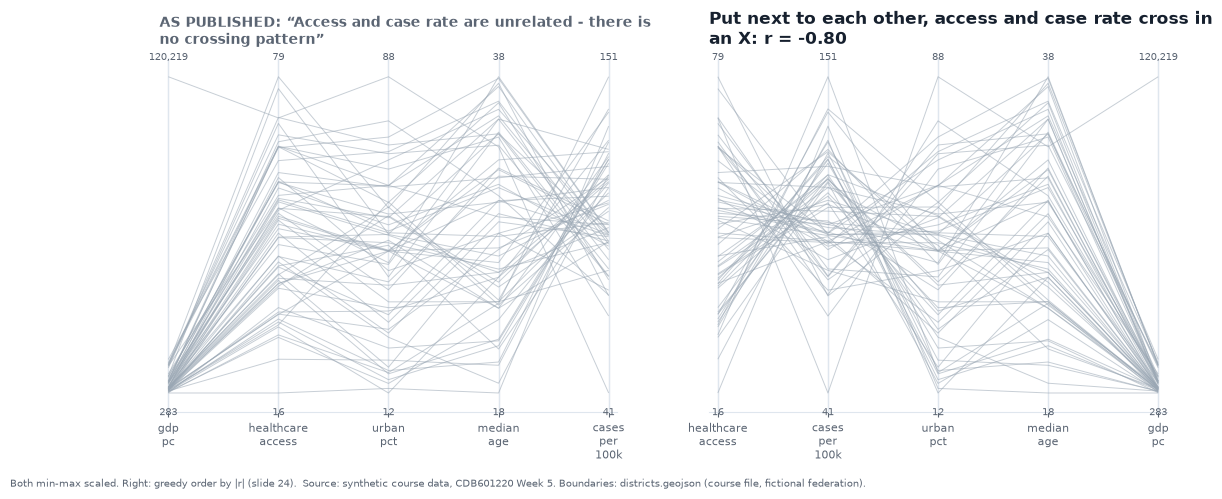

In [12]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6))
g.pcp(a, hi, NUM, "minmax")
published(a, "Access and case rate are unrelated - there is no crossing pattern")
g.pcp(b, hi, chain, "minmax")
b.set_title(wrap("Put next to each other, access and case rate cross in an X: r = -0.80"))
save(fig, "a4_axis_order.png", "Both min-max scaled. Right: greedy order by |r| (slide 24).")

**The redesign.** The same PCP and the same scaling, with the axis order **computed** by the greedy |r|
chain: access → cases → urban → median age → GDP. The X-shaped waist between the first two axes is the
negative correlation. Again, the fix is a decision, not a different chart.

---
## 5 · "There is a clear five-level gradient in incidence across the federation"

Recipe: rate per 100,000, five **quantile** classes, a five-step sequential ramp.

In [13]:
c5 = pd.read_csv(DATA / "case05_flat_rates.csv").assign(rate=per100k)
spread5 = (c5.rate.max() - c5.rate.min()) / c5.rate.mean()
print(f"{len(c5)} districts, rate {c5.rate.min():.2f} to {c5.rate.max():.2f} per 100k, spread {spread5:.1%} of the mean")
q = g.breaks(c5.rate, "quantile", 5)
print("quantile breaks:", np.round(q, 2).tolist())

24 districts, rate 31.07 to 33.40 per 100k, spread 7.2% of the mean
quantile breaks: [31.07, 31.49, 32.07, 32.51, 32.94, 33.4]


**Self-check:** 24 districts, 31.07 to 33.40 per 100,000, 7.2% of the mean. ✓

**The conclusion it invites.** A smooth gradient from light to dark districts, so there's a geography to
explain.

**The decoy.** "Quantile is a bad scheme, so use natural breaks." Natural breaks paints the same five
confident colours, because any five-class scheme fills five classes. Changing the *scheme* doesn't fix it.

In [14]:
pooled5 = c5.cases.sum() / c5.population.sum() * 1e5
lim = g.funnel_limits(c5.population, pooled5)
c5["lo"] = pooled5 - 1.96 * np.sqrt(pooled5 / 1e5 * c5.population) / c5.population * 1e5
c5["hi"] = pooled5 + 1.96 * np.sqrt(pooled5 / 1e5 * c5.population) / c5.population * 1e5
out = ((c5.rate < c5.lo) | (c5.rate > c5.hi)).sum()
print(f"pooled rate {pooled5:.2f}; class widths {np.round(np.diff(q), 2).tolist()} per 100k")
print(f"districts outside 95% Poisson limits: {out} of {len(c5)}")
print(f"for comparison, district_health rates span {dh.rate.min():.1f} to {dh.rate.max():.1f}")

pooled rate 32.25; class widths [0.41, 0.58, 0.44, 0.43, 0.46] per 100k
districts outside 95% Poisson limits: 0 of 24
for comparison, district_health rates span 30.4 to 76.5


**The mechanism.** The classes were cut to fit the data, not to mean anything. Quantile classes put
about five districts in each colour, however close the values are. Here the five classes are each about
**0.4 to 0.6 per 100,000 wide**, and the darkest district is just 7.5% above the lightest. **No** district
is outside the 95% Poisson limits around the pooled rate, so the whole "gradient" is the size of
sampling noise. Classification can't tell you whether there's a pattern. Only the spread can.

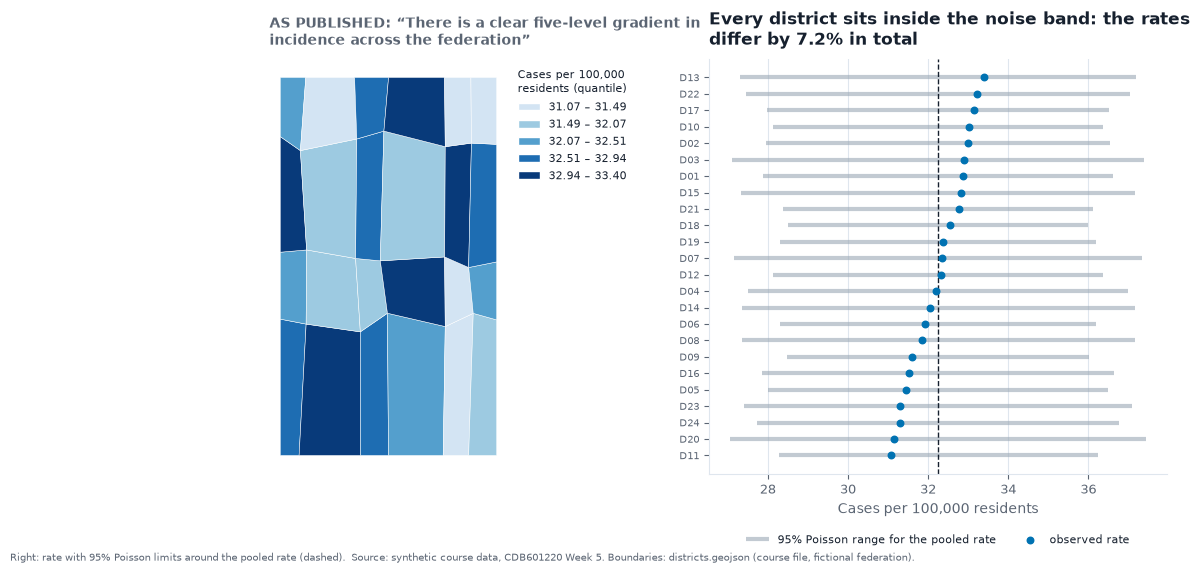

In [15]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 5.4))
g.choropleth(a, feats, dict(zip(c5.code, c5.rate)), "quantile", 5, fmt="{:.2f}",
             legend_title="Cases per 100,000\nresidents (quantile)")
published(a, "There is a clear five-level gradient in incidence across the federation")

srt = c5.sort_values("rate")
y = np.arange(len(srt))
b.hlines(y, srt.lo, srt.hi, color=GREY, lw=3, alpha=0.6, label="95% Poisson range for the pooled rate")
b.scatter(srt.rate, y, color=BLUE, zorder=3, s=22, label="observed rate")
b.axvline(pooled5, color=INK, lw=1, ls="--")
b.set_yticks(y, srt.code, fontsize=7)
b.set_xlabel("Cases per 100,000 residents")
b.grid(axis="y", visible=False)
b.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=8)
b.set_title(wrap(f"Every district sits inside the noise band: the rates differ by {spread5:.1%} in total"))
save(fig, "a5_quantile_flat.png", "Right: rate with 95% Poisson limits around the pooled rate (dashed).")

**The redesign.** Show the spread against what chance alone would produce: each district's rate inside
its 95% Poisson range. If a map is still wanted, the honest version is one class with a caption ("all 24
districts within 31–33 per 100,000; no district differs from the pooled rate"), not five.

---
## 6 · "Unit U32 is a hotspot — it is running at nearly five times the national rate"

Recipe: rate per 100,000 per unit, ranked, worst unit reported against the pooled rate.

In [16]:
sa = pd.read_csv(DATA / "smallarea_cases.csv").assign(rate=per100k)
pooled6 = sa.cases.sum() / sa.population.sum() * 1e5
worst = sa.loc[sa.rate.idxmax()]
big = sa[sa.population > 100_000]
print(f"{len(sa)} units, pooled {pooled6:.2f}; worst {worst.unit}: {worst.rate:.1f} ({worst.rate / pooled6:.1f}x) "
      f"from {worst.cases:.0f} cases in {worst.population:,.0f}")
print(f"{len(big)} units over 100,000 people: {big.rate.min():.1f} to {big.rate.max():.1f}")

40 units, pooled 8.72; worst U32: 40.9 (4.7x) from 9 cases in 22,000
10 units over 100,000 people: 5.5 to 12.0


**Self-check:** 40 units, pooled 8.72, U32 40.9 (4.7×) from 9 cases in 22,000, and the 10 big units between
5.5 and 12.0. ✓

**The conclusion it invites.** Something is happening in U32.

**The decoy.** "Nine cases could still be a real cluster." A single unit can't rule that out. But the data
dictionary states that **every unit has the same true rate**. Even without that fact, the funnel below
shows U32 is exactly what that rate would produce now and then.

In [17]:
sa["expected"] = pooled6 / 1e5 * sa.population
sa["lo"] = pooled6 - 1.96 * np.sqrt(sa.expected) / sa.population * 1e5
sa["hi"] = pooled6 + 1.96 * np.sqrt(sa.expected) / sa.population * 1e5
outside = sa[(sa.rate < sa.lo) | (sa.rate > sa.hi)]
small = sa[sa.population < 30_000]
print(f"U32 expected {sa.loc[sa.unit == 'U32', 'expected'].iloc[0]:.1f} cases, observed 9")
print(f"outside 95% limits: {outside.unit.tolist()} ({len(outside)} of 40; ~2 expected by chance)")
print(f"units under 30,000 people: rates {small.rate.min():.1f} to {small.rate.max():.1f}")

U32 expected 1.9 cases, observed 9
outside 95% limits: ['U32'] (1 of 40; ~2 expected by chance)
units under 30,000 people: rates 0.0 to 40.9


**The mechanism.** A small denominator makes a rate unstable. U32 expects about 1.9 cases at the pooled
rate, and 9 is high, but among 40 units at least one extreme small unit is what chance produces. The
small units scatter from 0 to 40.9, while every unit over 100,000 sits between 5.5 and 12.0. The ranking
picks out the noisiest unit, and in small-area data that's just the smallest one. Only one unit (U32) is
outside the 95% funnel, about what 40 units would give by chance at the 5% level.

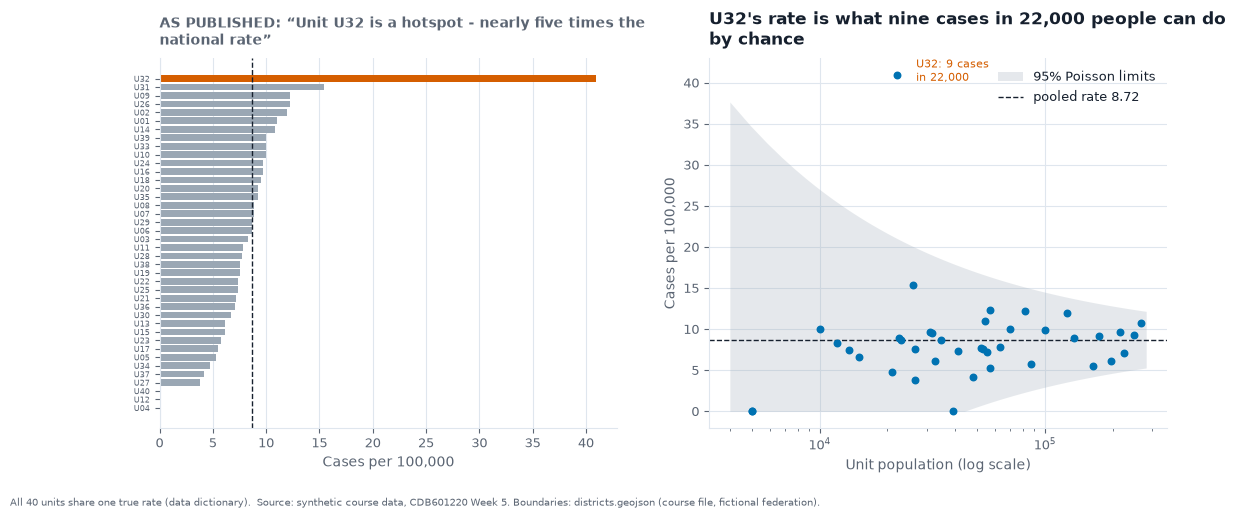

In [18]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.8))
srt = sa.sort_values("rate")
a.barh(srt.unit, srt.rate, color=[ORANGE if u == "U32" else GREY for u in srt.unit])
a.axvline(pooled6, color=INK, ls="--", lw=1)
a.tick_params(axis="y", labelsize=6)
a.set_xlabel("Cases per 100,000")
a.grid(axis="y", visible=False)
published(a, "Unit U32 is a hotspot - nearly five times the national rate")

fl = g.funnel_limits(np.linspace(sa.population.min() * 0.8, sa.population.max() * 1.05, 300), pooled6)
b.fill_between(fl.population, fl.lo, fl.hi, color=GREY, alpha=0.25, lw=0, label="95% Poisson limits")
b.axhline(pooled6, color=INK, ls="--", lw=1, label=f"pooled rate {pooled6:.2f}")
b.scatter(sa.population, sa.rate, color=BLUE, s=22, zorder=3)
b.annotate("U32: 9 cases\nin 22,000", (worst.population, worst.rate), xytext=(14, -4), textcoords="offset points",
           fontsize=8, color=ORANGE)
b.set_xscale("log")
b.set_xlabel("Unit population (log scale)")
b.set_ylabel("Cases per 100,000")
b.legend(loc="upper right")
b.set_title(wrap("U32's rate is what nine cases in 22,000 people can do by chance"))
save(fig, "a6_small_denominator.png", "All 40 units share one true rate (data dictionary).")

**The redesign.** A funnel plot: rate against the population behind it, with Poisson limits that widen as
population falls. U32 sits at the narrow neck where wild rates are normal. The bar chart ranked noise.

---
## 7 · "District income and case rate are only weakly related — r is about −0.31"

Recipe: correlate `income_pc_usd` with cases per 100,000 across the 24 districts.

In [19]:
r_d = np.corrcoef(dh.income_pc_usd, dh.rate)[0, 1]
zone = dh.groupby("zone").agg(cases=("cases", "sum"), population=("population", "sum"), income=("income_pc_usd", "mean"))
zone["rate"] = per100k(zone)
r_z = np.corrcoef(zone.income, zone.rate)[0, 1]
print(f"r by district (24 units): {r_d:+.3f}")
print(f"r by zone (6 units, mean district income vs pooled rate): {r_z:+.3f}")

r by district (24 units): -0.308
r by zone (6 units, mean district income vs pooled rate): -0.889


**Self-check:** r = −0.308 across 24 districts. ✓

**The conclusion it invites.** Income barely matters for the outbreak.

**The decoy.** "With n = 24 the estimate is just noisy." Sample size isn't what changes it. The *same
people and the same cases* give a very different r depending only on how they're grouped.

**The mechanism.** The modifiable areal unit problem: a correlation belongs to the units it was computed
on. Grouping the same 24 districts into the six coarse zones (`districts_coarse.geojson`) gives r =
**−0.889**. Aggregation averages away the within-zone variation and leaves the between-zone pattern, so r
grows. Neither number is "the" relationship: −0.31 describes districts and −0.89 describes zones. And
neither describes individuals, which would be the ecological fallacy.

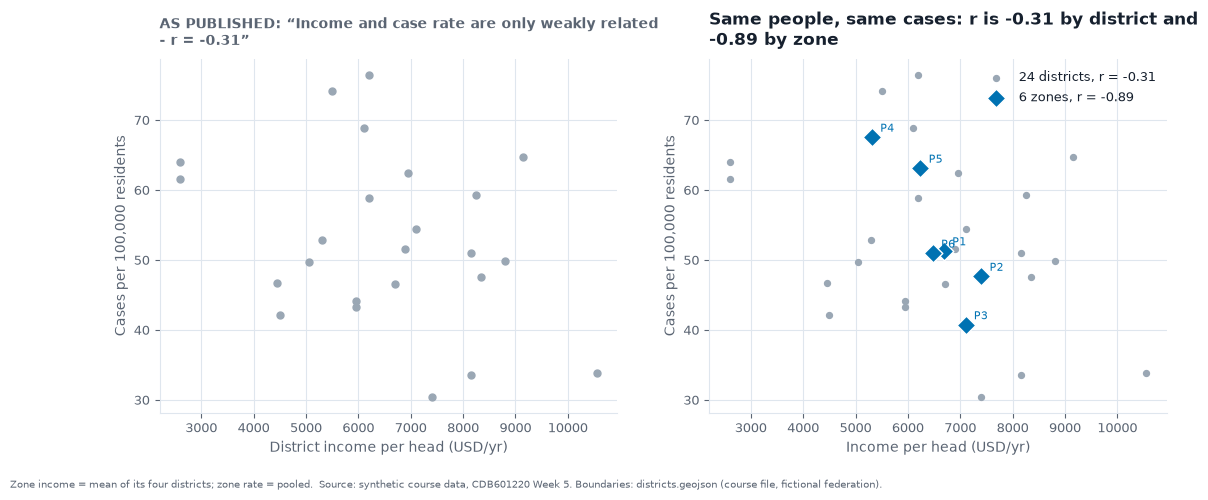

In [20]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6))
a.scatter(dh.income_pc_usd, dh.rate, color=GREY)
a.set_xlabel("District income per head (USD/yr)")
a.set_ylabel("Cases per 100,000 residents")
a.set_title(wrap(f"AS PUBLISHED: “Income and case rate are only weakly related - r = {r_d:.2f}”", 60),
            fontsize=10, color=SOFT)

b.scatter(dh.income_pc_usd, dh.rate, color=GREY, s=18, label=f"24 districts, r = {r_d:+.2f}")
b.scatter(zone.income, zone.rate, color=BLUE, s=90, marker="D", edgecolor="white", zorder=3,
          label=f"6 zones, r = {r_z:+.2f}")
for z, row in zone.iterrows():
    b.annotate(z, (row.income, row.rate), xytext=(6, 4), textcoords="offset points", fontsize=8, color=BLUE)
b.set_xlabel("Income per head (USD/yr)")
b.set_ylabel("Cases per 100,000 residents")
b.legend(loc="upper right")
b.set_title(wrap("Same people, same cases: r is -0.31 by district and -0.89 by zone"))
save(fig, "a7_maup.png", "Zone income = mean of its four districts; zone rate = pooled.")

**The redesign.** Report the correlation **at every scale you have**, on one chart, and name the unit next
to each r. `districts_alt.geojson` (same scale, different lines) carries no case data, so it can't be
used without inventing an allocation. I note that as the zoning half of MAUP and don't test it.

---
## 8 · "This is a rural outbreak — look how much of the map is dark"

Recipe: choropleth the rate in five natural breaks, then describe how much of the map is in the top two
classes.

In [21]:
e8 = g.breaks(dh.rate, "natural", 5)
cls = g.class_of(dh.rate, e8)
dark = cls >= 3
top5 = dh.nlargest(5, "population")
dens = dh.population / dh.area_km2
print(f"top-two classes: {dark.sum()} districts, {dh.area_km2[dark].sum() / dh.area_km2.sum():.1%} of the land, "
      f"{dh.population[dark].sum() / dh.population.sum():.1%} of the people")
print(f"five most populous districts: {top5.area_km2.sum() / dh.area_km2.sum():.1%} of the land, "
      f"{top5.population.sum() / dh.population.sum():.1%} of the people")
print(f"density spans {dens.min():.0f} to {dens.max():.0f} people/km2; r(rate, density) = {np.corrcoef(dh.rate, dens)[0, 1]:+.3f}")

top-two classes: 9 districts, 31.2% of the land, 26.5% of the people
five most populous districts: 12.6% of the land, 59.9% of the people
density spans 6 to 327 people/km2; r(rate, density) = +0.001


**Self-check:** the five most populous districts are 12.6% of the land and 59.9% of the people. ✓

**The conclusion it invites.** The dark colour covers wide, empty districts, so this is a rural problem.

**The decoy.** "The rate is right, so the map is right." The rate *is* right, and per district it's the
correct thing to colour. The problem isn't the number. It's how much ink each number gets.

**The mechanism.** A choropleth gives each district ink in proportion to its **land area**, not its people.
Big, thinly populated districts own the map: the five most populous districts are 59.9% of the people
but get 12.6% of the ink. "How much of the map is dark" measures land. And the "rural" story isn't in
the data either: r(rate, density) = **+0.001**, with density spanning 6 to 327 people/km².

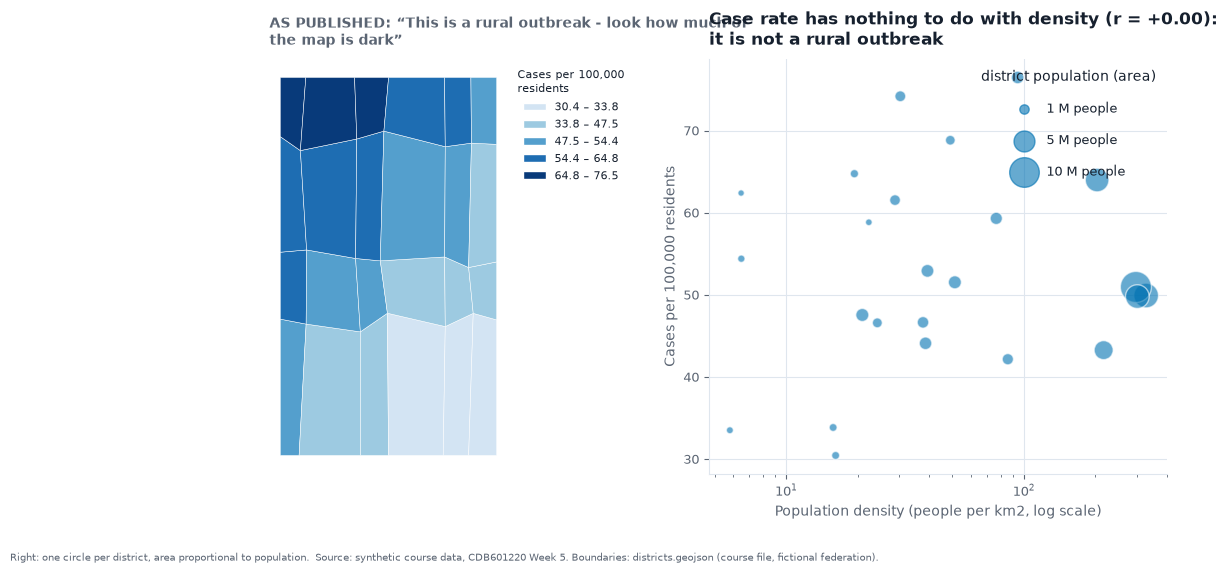

In [22]:
fig = plt.figure(figsize=(13, 5.4))
a = fig.add_subplot(1, 2, 1)
g.choropleth(a, feats, dict(zip(dh.code, dh.rate)), "natural", 5, fmt="{:.1f}",
             legend_title="Cases per 100,000\nresidents")
published(a, "This is a rural outbreak - look how much of the map is dark")
b = fig.add_subplot(1, 2, 2)
b.scatter(dens, dh.rate, s=dh.population / dh.population.max() * 500,
          color=BLUE, alpha=0.6, edgecolor="white")
b.set_xscale("log")
b.set_xlabel("Population density (people per km2, log scale)")
b.set_ylabel("Cases per 100,000 residents")
for v in (1e6, 5e6, 10e6):
    b.scatter([], [], s=v / dh.population.max() * 500, color=BLUE, alpha=0.6, label=f"{v / 1e6:g} M people")
b.legend(title="district population (area)", loc="upper right", labelspacing=1.4)
b.set_title(wrap("Case rate has nothing to do with density (r = +0.00): it is not a rural outbreak"))
save(fig, "a8_area_is_not_people.png", "Right: one circle per district, area proportional to population.")

**The redesign.** Ask the "rural?" question directly: rate against density, with each district's circle
sized by its population so the people count again. No relationship. (Part D3 adds the other fix the brief
names, a sorted bar chart beside the map.)

---
## 9 · "Region A is the stronger of the two — its profile encloses visibly more area"

Recipe: a radar chart, six axes in file order, both profiles filled, then compare the areas.

In [23]:
rp = pd.read_csv(DATA / "region_profiles.csv")


def radar_area(v):
    n = len(v)
    return 0.5 * np.sin(2 * np.pi / n) * sum(v[i] * v[(i + 1) % n] for i in range(n))


A, B = rp.region_a.to_numpy(), rp.region_b.to_numpy()
print(f"means: A {A.mean():.1f}, B {B.mean():.1f}, difference {A.mean() - B.mean():.2f}")
print(f"enclosed area in file order: A {radar_area(A):,.0f}, B {radar_area(B):,.0f}")

means: A 62.3, B 62.0, difference 0.33
enclosed area in file order: A 9,933, B 9,433


**Self-check:** means 62.3 and 62.0 (a difference of 0.33), areas 9,933 and 9,433. ✓

**The conclusion it invites.** A's shape is bigger, so A is the stronger region.

**The decoy.** "Area is a fair summary, because more area means higher scores." It would be, if area
depended only on the scores. It doesn't.

In [24]:
wins = []
for p in itertools.permutations(range(1, 6)):
    o = [0, *p]
    wins.append(radar_area(A[o]) - radar_area(B[o]))
wins = np.array(wins)
print(f"distinct orders (rotations removed): {len(wins)}; A encloses more in {(wins > 0).sum()}, B in {(wins < 0).sum()}")
print(f"area gap ranges from {wins.min():+,.0f} to {wins.max():+,.0f}")

distinct orders (rotations removed): 120; A encloses more in 78, B in 42
area gap ranges from -1,131 to +1,659


**The mechanism.** A radar's area is the sum of triangles formed by **adjacent** axes, so it depends on
which scores sit next to each other. That's an arbitrary choice. Across all 120 orders of the six axes,
A encloses more in 78 and **B encloses more in 42**, and the gap runs from −1,131 to +1,659. The means
differ by 0.33 points on a 0–100 scale. The "visibly more area" is mostly the axis order. The
real story is that the two regions have opposite strengths (A: funding and equipment, B: coverage and
training).

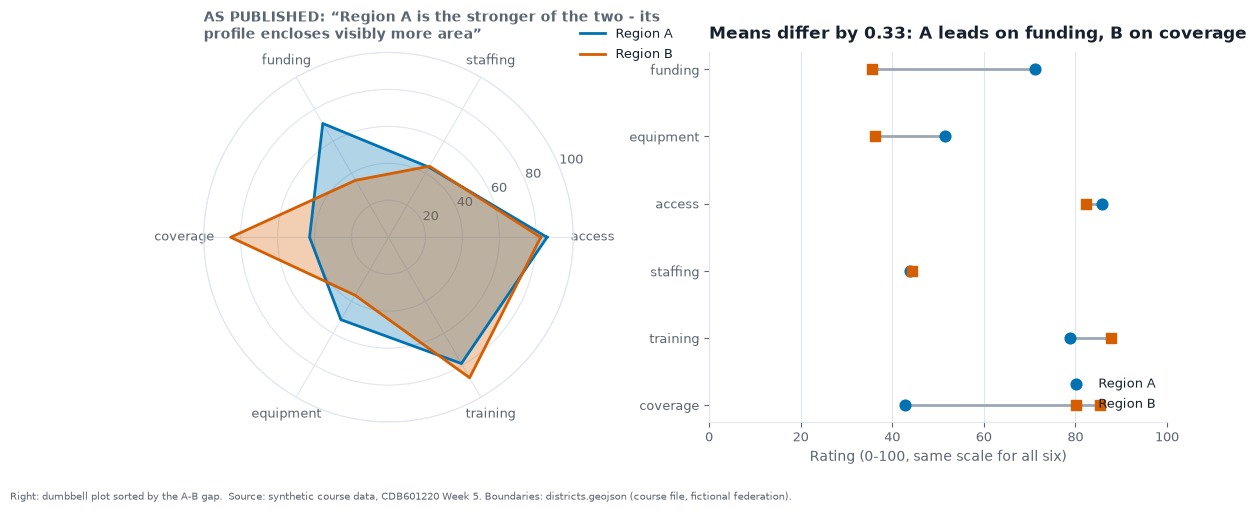

In [25]:
fig = plt.figure(figsize=(13, 4.8))
a = fig.add_subplot(1, 2, 1, projection="polar")
ang = np.linspace(0, 2 * np.pi, len(rp), endpoint=False)
for v, col, lab in ((A, BLUE, "Region A"), (B, ORANGE, "Region B")):
    a.fill(np.r_[ang, ang[0]], np.r_[v, v[0]], color=col, alpha=0.3)
    a.plot(np.r_[ang, ang[0]], np.r_[v, v[0]], color=col, label=lab)
a.set_xticks(ang, rp.indicator)
a.set_ylim(0, 100)
a.legend(loc="upper right", bbox_to_anchor=(1.3, 1.1))
published(a, "Region A is the stronger of the two - its profile encloses visibly more area")

b = fig.add_subplot(1, 2, 2)
srt = rp.assign(gap=rp.region_a - rp.region_b).sort_values("gap")
y = np.arange(len(srt))
b.hlines(y, srt.region_a, srt.region_b, color=GREY, lw=2)
b.scatter(srt.region_a, y, color=BLUE, s=60, zorder=3, label="Region A", marker="o")
b.scatter(srt.region_b, y, color=ORANGE, s=60, zorder=3, label="Region B", marker="s")
b.set_yticks(y, srt.indicator)
b.set_xlim(0, 100)
b.set_xlabel("Rating (0-100, same scale for all six)")
b.grid(axis="y", visible=False)
b.legend(loc="lower right")
b.set_title(wrap(f"Means differ by {A.mean() - B.mean():.2f}: A leads on funding, B on coverage"))
save(fig, "a9_radar_order.png", "Right: dumbbell plot sorted by the A-B gap.")

**The redesign.** A dumbbell plot puts both regions on a common **position** scale, the best channel,
sorted by the gap. Each comparison is read directly and doesn't depend on any order of axes.

---
## Summary

| # | Claim | The lying channel or boundary | The number |
|---|---|---|---|
| 1 | Population unrelated to access | Value drives **radius** (`s = pop**2`) | Area ratio 346,921× instead of 589×; 9 countries ≤ a point |
| 2 | Outbreak around the capital | Raw-count choropleth = population map | r(cases, pop) +0.986; top-3 overlap 0 |
| 3 | GDP barely varies | Min–max scaling flattened by one outlier | 58/60 below 0.10; real p10–p90 spread 11× |
| 4 | Access and cases unrelated | Axis order separates the pair | r = −0.799, three axes apart |
| 5 | Five-level gradient | Five quantile classes over a 7.2% spread | 0 of 24 outside Poisson limits |
| 6 | U32 hotspot | Small-denominator rate | 9 cases in 22,000; big units 5.5–12.0 |
| 7 | Income weakly related | Correlation at one areal scale (MAUP) | −0.308 by district, −0.889 by zone |
| 8 | Rural outbreak | Land area read as people | Top 5 populous: 12.6% of land, 59.9% of people |
| 9 | Region A stronger | Radar area depends on axis order | A wins 78 of 120 orders, B wins 42; means differ by 0.33 |

Cases **3 and 4** keep the chart and change a decision inside it (the scaling, the axis order), and so
does case **1** (area instead of radius). The other six need a different view of the same numbers.